# Explainable Machine-Learning and Predictive Statistics for Sustainable Photovoltaic Power Prediction on Areal Meteorological Variables
Sajjad Nematzadeh, 
Vedat Esen

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [37]:
df = pd.read_csv(fr'data/meta_h_mlp_95.csv', index_col=None)
df['iteration'] = ((df['index']-1)/(30.0)).astype(int)
df['cols'] = pd.read_csv(fr'data/meta_h_mlp_95.csv', dtype=object)['cols']

X_cols = np.array(['temperature_2m', 'relative_humidity_2m', 'apparent_temperature',
                   'wind_speed_10m', 'wind_direction_10m',
                   'shortwave_radiation_instant', 'direct_radiation_instant', 'diffuse_radiation_instant',
                   'direct_normal_irradiance',
                   'direct_normal_irradiance_instant', 'global_tilted_irradiance_instant', 'terrestrial_radiation_instant'])

df

,index,cols,features_count,score,train_mse,val_mse,test_mse,train_r2,val_r2,test_r2,iteration
0,0,011111011111,10,-0.819578,0.005879,0.005376,0.005678,0.903553,0.910463,0.906574,0
1,1,101011010101,7,-0.821568,0.006537,0.006033,0.006350,0.892755,0.899529,0.895510,0
2,2,111110111000,8,-0.813695,0.006842,0.006350,0.006587,0.887749,0.894254,0.891609,0
3,3,011111011100,8,-0.826830,0.005982,0.005486,0.005747,0.901870,0.908628,0.905435,0
4,4,011100001111,7,-0.831094,0.005894,0.005367,0.005741,0.903306,0.910611,0.905537,0
...,...,...,...,...,...,...,...,...,...,...,...
912,912,000100001110,4,-0.843301,0.005930,0.005408,0.005759,0.902726,0.909932,0.905229,30
913,913,001100000101,4,-0.839665,0.006196,0.005682,0.005992,0.898347,0.905372,0.901401,30
914,914,000000010000,1,-0.845591,0.006617,0.006139,0.006412,0.891453,0.897756,0.894481,30
915,915,001100110001,5,-0.833792,0.006309,0.005830,0.006101,0.896508,0.902903,0.899606,30


<Axes: xlabel='iteration', ylabel='features_count'>

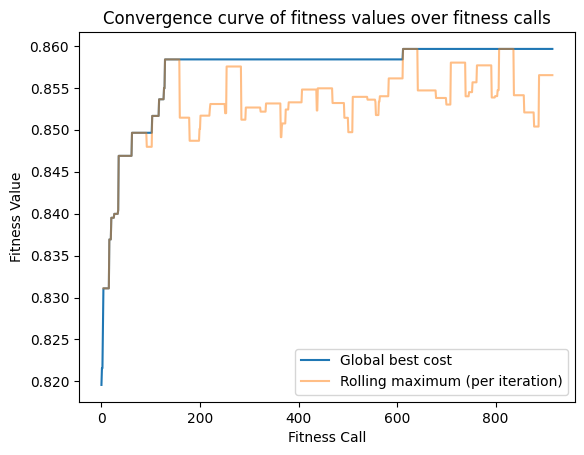

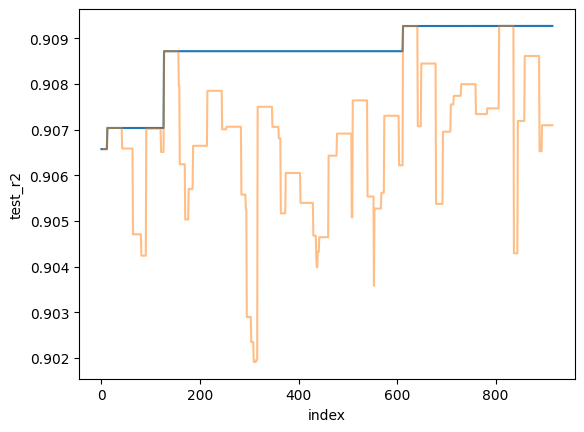

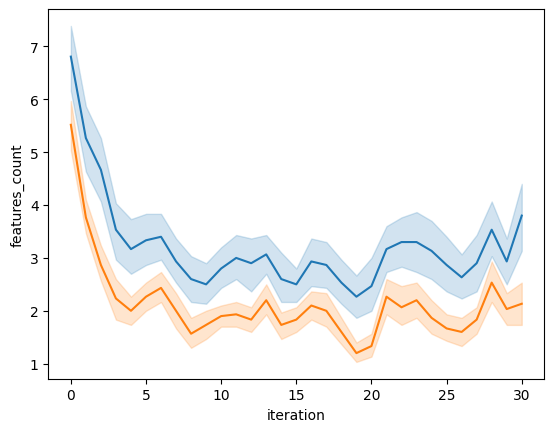

In [ ]:
vdf = df[:-1]

f, ax = plt.subplots(1, 1)
sns.lineplot(vdf, x='index', y=-vdf['score'].cummin(), ax=ax, label='Global best cost')
sns.lineplot(vdf, x='index', y=-vdf['score'].rolling(30, min_periods=5).min(), alpha=0.5, ax=ax, label='Rolling maximum (per iteration)')
plt.title('Convergence curve of fitness values over fitness calls')
plt.xlabel('Fitness Call')
plt.ylabel('Fitness Value')
ax.legend()


plt.figure()
# sns.lineplot(vdf, x='iteration', y=vdf['test_r2'].mean())
sns.lineplot(vdf, x='index', y=vdf['test_r2'].cummax())
sns.lineplot(vdf, x='index', y=vdf['test_r2'].rolling(30, min_periods=5).max(), alpha=0.5)


# sns.lineplot(vdf, x='iteration', y=vdf['test_r2'])
plt.figure()
sns.lineplot(vdf, x='iteration', y=vdf['features_count'])
sns.lineplot(vdf, x='iteration', y=vdf['features_count'].rolling(3).min())

In [54]:
df['avg_r2'] = (df['train_r2']+df['val_r2']+df['test_r2'])/3
df = df.sort_values(['avg_r2'], ascending=False).reset_index(drop=True)
df

,index,cols,features_count,score,train_mse,val_mse,test_mse,train_r2,val_r2,test_r2,iteration,avg_r2
0,612,001000000000,1,-0.859638,0.005688,0.005208,0.005514,0.906686,0.913260,0.909268,20,0.909738
1,127,001000010000,2,-0.854948,0.005718,0.005221,0.005547,0.906194,0.913044,0.908717,4,0.909318
2,807,000000010000,1,-0.859640,0.005753,0.005252,0.005514,0.905624,0.912536,0.909270,26,0.909144
3,859,000100110001,4,-0.846515,0.005743,0.005232,0.005554,0.905788,0.912871,0.908612,28,0.909090
4,649,001100000000,2,-0.854692,0.005751,0.005286,0.005564,0.905650,0.911974,0.908447,21,0.908690
...,...,...,...,...,...,...,...,...,...,...,...,...
912,113,100000000100,2,-0.820296,0.007943,0.007484,0.007764,0.869690,0.875367,0.872242,3,0.872433
913,629,001110101000,5,-0.806178,0.008102,0.007673,0.007868,0.867081,0.872216,0.870538,20,0.869945
914,584,000000000010,1,-0.819422,0.008269,0.007759,0.008086,0.864341,0.870780,0.866935,19,0.867352
915,14,111110111000,8,-0.790465,0.008295,0.007830,0.008073,0.863914,0.869598,0.867156,0,0.866889


In [86]:
bests = np.array([list(c) for c in df[:5]['cols'].values]).astype(bool)
[list(X_cols[bests[i]]) for i in range(bests.shape[0])]

[['apparent_temperature'],
 ['apparent_temperature', 'diffuse_radiation_instant'],
 ['diffuse_radiation_instant'],
 ['wind_speed_10m',
  'direct_radiation_instant',
  'diffuse_radiation_instant',
  'terrestrial_radiation_instant'],
 ['apparent_temperature', 'wind_speed_10m']]